In [ ]:
import json, os, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, TensorDataset

import pipeline as pl      # Task 2: cached arrays, split, prepare(), augment()
import model_defs as md    # Task 3: model builders + hyperparameter configs

MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True) # One checkpoint + history per run
RESULTS_FILE = Path("results.csv") # Experiment log for Task 6

# Defines a reusable helper function that resets the random seed across functions
def seed_everything(seed=pl.SEED):
    """Reset every RNG this notebook touches (Python, NumPy, torch) so a run
    is repeatable: identical weight init, batch order and augmentation draws."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

print("torch threads:", torch.get_num_threads(), "| logical cores:", os.cpu_count())

torch threads: 10 | logical cores: 12


In [ ]:
# Load all pre-processed and split tensors, class names, and normalization stats from disk
data = pl.load_cached_data()
X_tr, y_tr = data["X_tr"], data["y_tr"]
X_va, y_va = data["X_va"], data["y_va"]
classes, STATS = data["classes"], data["stats"]
NUM_CLASSES = len(classes)
print(f"train {tuple(X_tr.shape)} | validation {tuple(X_va.shape)} | classes: {classes}")

# Creates a dedicated PyTorch random number generator, wraps the training tensors into a TensorDataset, 
# and builds a DataLoader that shuffles the data batches anew on every epoch
g = torch.Generator(); g.manual_seed(pl.SEED)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=128,
                          shuffle=True, generator=g)
print("batches per epoch:", len(train_loader))

train (50916, 3, 64, 64) | validation (12729, 3, 64, 64) | classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
batches per epoch: 398


In [ ]:
# Inference helpers

# Uses @torch.no_grad() to disable gradient tracking to save memory
@torch.no_grad()
def predict_logits(model, X, stats, tta=False, bs=256): # Processes inputs in memory-safe chunks
    """Batched forward pass over a uint8 tensor; returns raw scores (logits).
    tta=True also scores the horizontally mirrored image and averages the two
    logits (test-time augmentation). A mirror image keeps the same class
    (a flipped cat eye is still a cat eye), so averaging reduces prediction
    variance at zero training cost."""
    model.eval() # eval mode = dropout off, BatchNorm uses fixed running statistics
    out = []
    for i in range(0, len(X), bs):
        x = pl.prepare(X[i:i + bs], False, stats) # Same deterministic path as val/test
        lg = model(x)
        if tta:
            lg = (lg + model(x.flip(3))) / 2 # Flip(3) mirrors the width axis
        out.append(lg)
    return torch.cat(out)

def evaluate(model, X, y, stats, tta=False):
    """One-pass validation metrics. Macro-F1 weights every class equally,
    so the four 9% classes count as much as CatEye — the right companion
    to accuracy given the 2.4x imbalance found in Task 1."""
    lg = predict_logits(model, X, stats, tta) # Computes raw logits using the prediction function
    pred = lg.argmax(1) # Extracts the predicted class via .argmax(1)
    return dict(loss=F.cross_entropy(lg, y).item(),
                acc=accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, average="macro"),
                pred=pred.numpy(), logits=lg)

In [ ]:
# Training loop
def train_model(name, epochs=None, use_aug=True, class_weights=False,
                patience=3, tag="", max_steps=None):
    """Train one model config. Returns (model, history, best_epoch_index).

    Overfitting/underfitting management built into this loop:
      augmentation (train batches only)   -> more effective data, fights overfitting
      weight decay via AdamW              -> penalises large weights, fights overfitting
      dropout + batch norm (in the models)-> regularisation / stable activations
      OneCycle LR schedule                -> fast convergence, anneals to a precise optimum
      best-checkpoint on VALIDATION loss  -> keeps the most general weights, not the last
      early stopping (patience=3)         -> stops once validation stops improving
    """
    cfg = md.MODEL_CONFIGS[name] # Pulls configuration parameters for the specified model architecture
    epochs = epochs or cfg["epochs"]
    run = name + tag # Unique names mean unique checkpoint/history files
    seed_everything(pl.SEED) # Every run starts from identical conditions

    model = cfg["build"]() # For ResNet18 this loads ImageNet weights (cached)
    stats = STATS[cfg["stats"]] # ResNet uses ImageNet stats. The CNN uses our train stats

    weight = None
    if class_weights:
        cnt = torch.bincount(y_tr, minlength=NUM_CLASSES).float()
        weight = cnt.sum() / (NUM_CLASSES * cnt)
    criterion = nn.CrossEntropyLoss(weight=weight)
    
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    # AdamW applies decoupled weight decay regularization, which penalizes excessively large weights and helps fight overfitting

    sched = torch.optim.lr_scheduler.OneCycleLR( # ramps the learning rate up to its peak value over the first 25% of training
        opt, max_lr=cfg["lr"], total_steps=epochs * len(train_loader), pct_start=0.25)

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "lr", "sec"]}
    best_val, best_ep, bad = float("inf"), -1, 0

    # Batch Training and Backpropagation Loop
    for ep in range(epochs):
        t0 = time.time()
        model.train() # Train mode: dropout active, BN updates running stats
        tl = tc = n = 0
        for step, (xb, yb) in enumerate(train_loader):
            if max_steps and step >= max_steps:
                break
            x = pl.prepare(xb, True, stats, use_aug)
            logits = model(x)
            loss = criterion(logits, yb)
            opt.zero_grad(set_to_none=True) # Clear stale gradients (set_to_none is cheaper)
            loss.backward() # Backpropagation
            opt.step() # Update weights
            sched.step() # The schedule advances per step, not per epoch
            tl += loss.item() * len(yb) # Accumulate weighted sums -> exact epoch means
            tc += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
            if (step + 1) % 100 == 0:
                print(f"  ep {ep+1} step {step+1}/{len(train_loader)} running loss {tl/n:.3f}")

        # Evaluates the model on the validation set at the end of every epoch
        v = evaluate(model, X_va, y_va, stats) # Validation every epoch
        for k, val in zip(hist, [tl / n, tc / n, v["loss"], v["acc"], v["macro_f1"],
                                 opt.param_groups[0]["lr"], time.time() - t0]):
            hist[k].append(val)
        print(f"{run} ep {ep+1:2d}/{epochs} | train loss {tl/n:.3f} acc {tc/n:.3f} | "
              f"val loss {v['loss']:.3f} acc {v['acc']:.3f} F1 {v['macro_f1']:.3f} "
              f"| lr {opt.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s")

        # Checkpoint on the LOWEST validation loss
        # Validation loss is the honest generalisation signal, while training loss always falls, even when the model starts memorising
        if v["loss"] < best_val:
            best_val, best_ep, bad = v["loss"], ep, 0
            torch.save(model.state_dict(), MODEL_DIR / f"{run}.pt")
        else:
            bad += 1                                 # no improvement -> one strike
            if bad >= patience:                      # `patience` strikes -> stop
                print(f"early stopping at epoch {ep+1} (best epoch was {best_ep+1})")
                break

    # Reload the best weights so the returned model IS the best checkpoint.
    model.load_state_dict(torch.load(MODEL_DIR / f"{run}.pt"))
    with open(MODEL_DIR / f"{run}_history.json", "w") as f:
        json.dump(hist, f) # History survives kernel restarts
    return model, hist, best_ep

In [ ]:
# Learning curves and experiment log
# Plots side-by-side line graphs tracking training versus validation loss and accuracy across every epoch
def plot_curves(hist, title, best_ep=None):
    """Train vs validation loss and accuracy per epoch — the Task 4 evidence.
      both curves high and flat                -> underfitting (train longer/bigger)
      train improves while val stalls or rises -> overfitting (more regularisation)
    The dashed line marks the checkpointed (best-val-loss) epoch. Note: training
    accuracy is measured WITH augmentation and dropout active, so early epochs
    can show train accuracy below validation — that is expected, not a bug."""
    e = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(e, hist["train_loss"], "o-", label="train")
    ax[0].plot(e, hist["val_loss"], "o-", label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(e, hist["train_acc"], "o-", label="train")
    ax[1].plot(e, hist["val_acc"], "o-", label="validation")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    if best_ep is not None:
        for a in ax: a.axvline(best_ep + 1, color="grey", ls="--", lw=1)
    plt.tight_layout(); plt.show()
    # Because data augmentation and dropout are active during training, training accuracy can occasionally appear lower than validation accuracy in early epochs

# Evaluates the final model checkpoint on the validation set, compiles a dictionary of key metrics, checks if results.csv already exists, appends or updates the row for that specific run, and saves it back to disk
def log_result(run, model, hist, best_ep, stats, notes=""):
    """Append one row per experiment to results.csv. It RE-LOADS the file if it
    already exists, so the log survives kernel restarts between experiments
    (a plain in-memory list would be wiped every time you reopen the notebook)."""
    v = evaluate(model, X_va, y_va, stats)
    row = dict(run=run,
               val_loss=round(v["loss"], 4), val_acc=round(v["acc"], 4),
               val_macro_f1=round(v["macro_f1"], 4),
               final_train_acc=round(hist["train_acc"][best_ep], 4),  # caveat: aug+dropout active
               epochs_run=len(hist["val_loss"]), best_epoch=best_ep + 1,
               minutes=round(sum(hist["sec"]) / 60, 1), notes=notes)
    table = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table = table.drop_duplicates("run", keep="last")   # rerunning an experiment updates its row
    table.to_csv(RESULTS_FILE, index=False)
    return table

In [6]:
# Prove the whole loop works
# Trains only 3 mini-batches, then runs one full validation pass
# If this prints sensible, decreasing-ish numbers and saves a checkpoint, the long runs are safe to start
_, h_smoke, _ = train_model("custom_cnn", epochs=1, max_steps=3, tag="_smoke")
print("smoke test OK — checkpoints and validation pass work end-to-end")

custom_cnn_smoke ep  1/1 | train loss 2.152 acc 0.125 | val loss 2.080 acc 0.091 F1 0.021 | lr 8.4e-05 | 43s
smoke test OK — checkpoints and validation pass work end-to-end


  ep 1 step 100/398 running loss 0.857
  ep 1 step 200/398 running loss 0.506
  ep 1 step 300/398 running loss 0.381
resnet18_pt ep  1/6 | train loss 0.324 acc 0.890 | val loss 0.087 acc 0.971 F1 0.970 | lr 7.6e-04 | 706s
  ep 2 step 100/398 running loss 0.118
  ep 2 step 200/398 running loss 0.120
  ep 2 step 300/398 running loss 0.114
resnet18_pt ep  2/6 | train loss 0.109 acc 0.964 | val loss 0.100 acc 0.966 F1 0.966 | lr 9.7e-04 | 696s
  ep 3 step 100/398 running loss 0.079
  ep 3 step 200/398 running loss 0.081
  ep 3 step 300/398 running loss 0.079
resnet18_pt ep  3/6 | train loss 0.076 acc 0.975 | val loss 0.043 acc 0.985 F1 0.985 | lr 7.5e-04 | 447s
  ep 4 step 100/398 running loss 0.054
  ep 4 step 200/398 running loss 0.051
  ep 4 step 300/398 running loss 0.048
resnet18_pt ep  4/6 | train loss 0.046 acc 0.985 | val loss 0.032 acc 0.989 F1 0.988 | lr 4.1e-04 | 444s
  ep 5 step 100/398 running loss 0.032
  ep 5 step 200/398 running loss 0.030
  ep 5 step 300/398 running loss 0

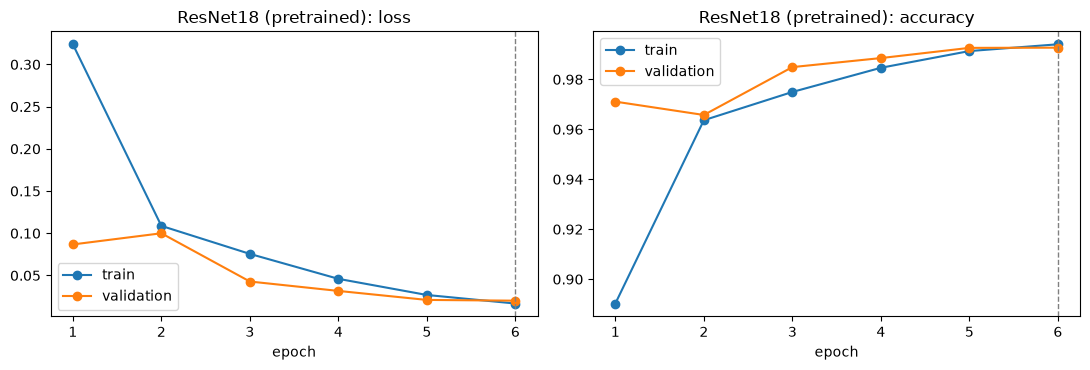

,run,val_loss,val_acc,val_macro_f1,final_train_acc,epochs_run,best_epoch,minutes,notes
0,resnet18_pt,0.0201,0.9927,0.9925,0.994,6,6,53.0,"transfer learning, augmentation on"


In [7]:
# Experiment A: ResNet18 (ImageNet-pretrained)
res, h_res, b_res = train_model("resnet18_pt")
plot_curves(h_res, "ResNet18 (pretrained)", b_res)
log_result("resnet18_pt", res, h_res, b_res,
           STATS[md.MODEL_CONFIGS["resnet18_pt"]["stats"]], "transfer learning, augmentation on")

  ep 1 step 100/398 running loss 1.684
  ep 1 step 200/398 running loss 1.414
  ep 1 step 300/398 running loss 1.199
custom_cnn ep  1/12 | train loss 1.040 acc 0.630 | val loss 0.584 acc 0.789 F1 0.773 | lr 5.6e-04 | 298s
  ep 2 step 100/398 running loss 0.420
  ep 2 step 200/398 running loss 0.371
  ep 2 step 300/398 running loss 0.347
custom_cnn ep  2/12 | train loss 0.324 acc 0.892 | val loss 0.271 acc 0.905 F1 0.910 | lr 1.5e-03 | 296s
  ep 3 step 100/398 running loss 0.220
  ep 3 step 200/398 running loss 0.212
  ep 3 step 300/398 running loss 0.206
custom_cnn ep  3/12 | train loss 0.197 acc 0.933 | val loss 0.310 acc 0.896 F1 0.889 | lr 2.0e-03 | 295s
  ep 4 step 100/398 running loss 0.156
  ep 4 step 200/398 running loss 0.152
  ep 4 step 300/398 running loss 0.146
custom_cnn ep  4/12 | train loss 0.144 acc 0.950 | val loss 0.187 acc 0.933 F1 0.927 | lr 1.9e-03 | 297s
  ep 5 step 100/398 running loss 0.122
  ep 5 step 200/398 running loss 0.118
  ep 5 step 300/398 running loss 0

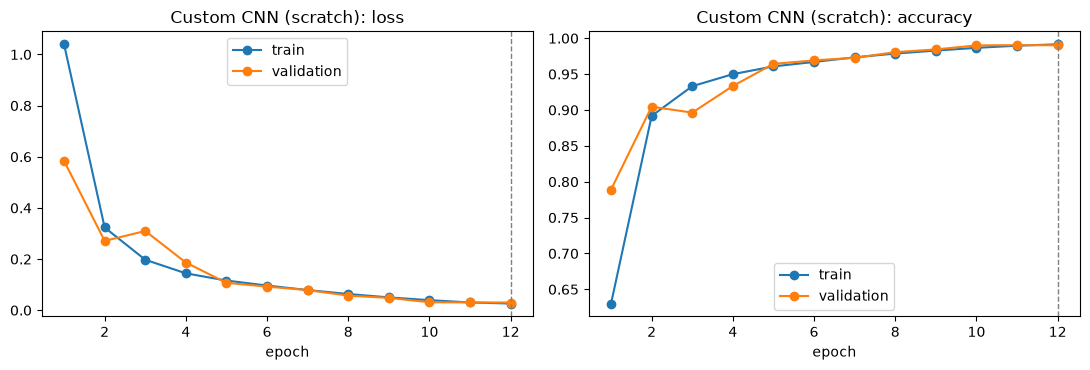

,run,val_loss,val_acc,val_macro_f1,final_train_acc,epochs_run,best_epoch,minutes,notes
0,resnet18_pt,0.0201,0.9927,0.9925,0.9940,6,6,53.0,"transfer learning, augmentation on"
1,custom_cnn,0.0300,0.9903,0.9900,0.9916,12,12,59.5,"from scratch, augmentation on"


In [8]:
# Experiment B: Custom CNN trained from scratch

cnn, h_cnn, b_cnn = train_model("custom_cnn")
plot_curves(h_cnn, "Custom CNN (scratch)", b_cnn)
log_result("custom_cnn", cnn, h_cnn, b_cnn, STATS["train"], "from scratch, augmentation on")